## Objectif
Analyser et consolider les données Context_QA
## Contenu
- Chargement des données depuis les trois sources
- Analyse exploratoire des données (EDA)
- Statistiques sur les contextes, questions et réponses
- Visualisations


#### Chargement des données

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import arabic_reshaper
from bidi.algorithm import get_display

In [2]:
df1 = pd.read_csv("dataset\\data1\\Final\\QA-Labled-Data_final.csv")
df3 = pd.read_csv("dataset\\\data3\mixed_dataset_grp_3.csv")
df2_1 = pd.read_json("dataset\\data2\\gold_dataset.json")
df2_2 = pd.read_json("dataset\\data2\\silver_dataset.json")

<>:2: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
C:\Users\exe\AppData\Local\Temp\ipykernel_31740\1830283762.py:2: SyntaxWarning: invalid escape sequence '\d'
  df3 = pd.read_csv("dataset\\\data3\mixed_dataset_grp_3.csv")


In [3]:
df1.rename(columns={'Question':'question','Answer':'answer'},inplace=True)

In [4]:
df = pd.concat([df1,df2_1,df2_2,df3])

In [5]:
df.drop(columns=['type'],inplace= True)

In [6]:
df.shape

(23702, 3)

#### Longueur contexts/questions/reponses

In [7]:
print('\n' + '='*80)
print('EXEMPLES DE DONNÉES')
print('='*80)

for idx in range(2):
    print(f" CONTEXTE:")
    print(f"  {df.iloc[idx]['context']}")
    print(f"\n  QUESTION:")
    print(f"  {df.iloc[idx]['question']}")
    print(f"\n  RÉPONSE:")
    print(f"  {df.iloc[idx]['answer']}")
    print()


EXEMPLES DE DONNÉES
 CONTEXTE:
  حصلت “كود” على تفاصيل اتهام مصطفى لخصم رئيس جماعة إيموزار كندر بشبهة “اختلاس وتبديد أموال عمومية”، وهي القضية التي شرعت الفرقة الجهوية للشرطة القضائية بفاس في إجراء الأبحاث والتحريات بشأنها.

  QUESTION:
  شنو هي التهمة اللي موجهة لمصطفى لخصم رئيس جماعة إيموزار كندر؟

  RÉPONSE:
  اختلاس وتبديد أموال عمومية

 CONTEXTE:
  فتصريح لقناة العربية، قال مستشار شؤون الشرق الأوسط في الإدارة الأميركية، مسعد بولس، بلي ميريكان متابعة الأوضاع فمنطقة المغرب العربي، وخصوصا الاوضاع بين الجزائر والمغرب.

  QUESTION:
  فإنا قناة عطى مسعد بولس التصريح ديالو؟

  RÉPONSE:
  قناة العربية



In [8]:
df['context'] = df['context'].fillna('')
df['question'] = df['question'].fillna('')
df['answer'] = df['answer'].fillna('')

df['context_len'] = df['context'].apply(lambda x: len(str(x).split()))
df['question_len'] = df['question'].apply(lambda x: len(str(x).split()))
df['answer_len'] = df['answer'].apply(lambda x: len(str(x).split()))

print("=== STATISTIQUES DES MOTS (CONTEXT) ===")
print(f"Minimum : {df['context_len'].min()}")
print(f"Maximum : {df['context_len'].max()}")
print(f"Moyenne : {df['context_len'].mean():.2f}\n")

print("=== STATISTIQUES DES MOTS (QUESTION) ===")
print(f"Minimum : {df['question_len'].min()}")
print(f"Maximum : {df['question_len'].max()}")
print(f"Moyenne : {df['question_len'].mean():.2f}\n")

print("=== STATISTIQUES DES MOTS (REPONSE) ===")
print(f"Minimum : {df['answer_len'].min()}")
print(f"Maximum : {df['answer_len'].max()}")
print(f"Moyenne : {df['answer_len'].mean():.2f}")

=== STATISTIQUES DES MOTS (CONTEXT) ===
Minimum : 4
Maximum : 593
Moyenne : 32.13

=== STATISTIQUES DES MOTS (QUESTION) ===
Minimum : 1
Maximum : 25
Moyenne : 8.61

=== STATISTIQUES DES MOTS (REPONSE) ===
Minimum : 1
Maximum : 28
Moyenne : 2.92


In [9]:
print(df['context_len'].describe())

count    23702.000000
mean        32.130580
std         15.565632
min          4.000000
25%         24.000000
50%         30.000000
75%         38.000000
max        593.000000
Name: context_len, dtype: float64


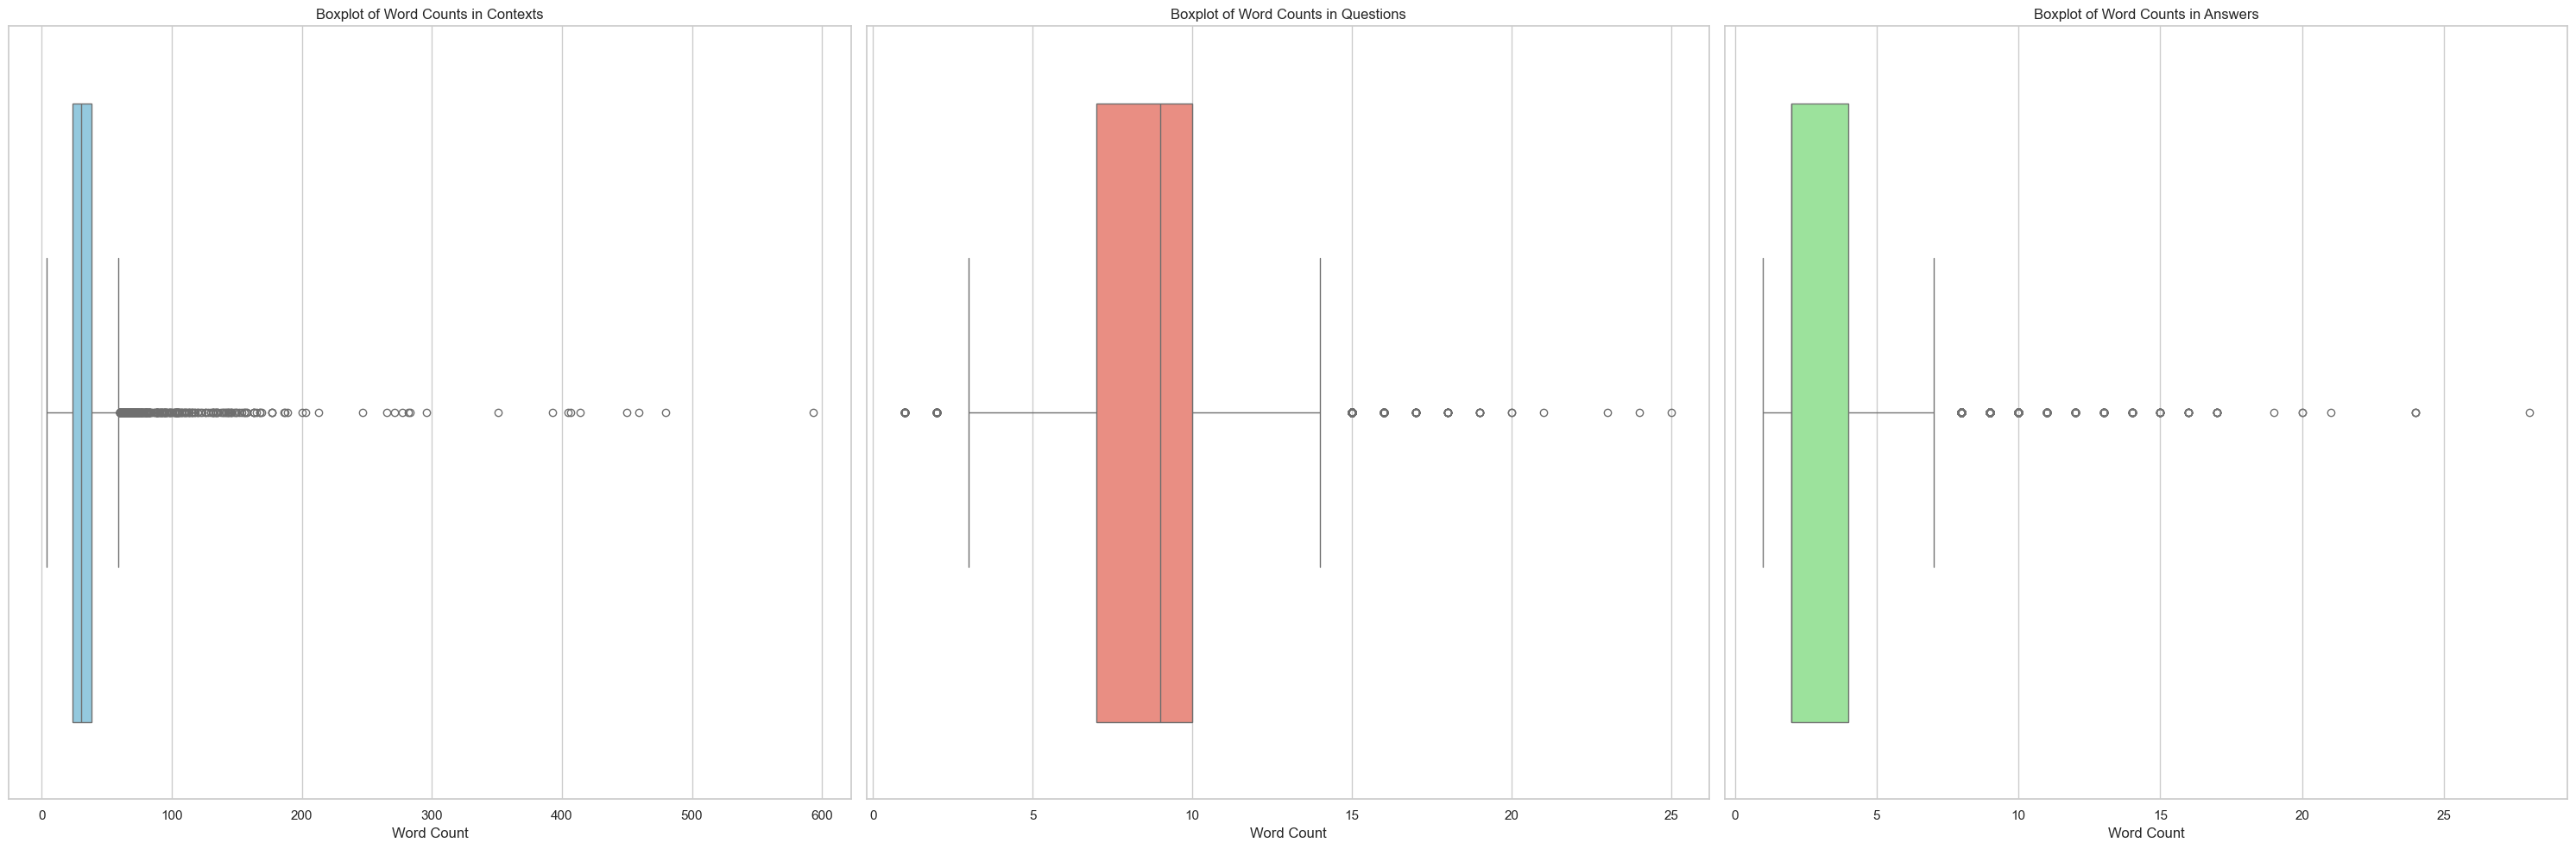

In [10]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(30, 10))

sns.boxplot(x=df['context_len'], ax=axes[0], color="skyblue")
axes[0].set_title('Boxplot of Word Counts in Contexts')
axes[0].set_xlabel('Word Count')

sns.boxplot(x=df['question_len'], ax=axes[1], color="salmon")
axes[1].set_title('Boxplot of Word Counts in Questions')
axes[1].set_xlabel('Word Count')

sns.boxplot(x=df['answer_len'], ax=axes[2], color="lightgreen")
axes[2].set_title('Boxplot of Word Counts in Answers')
axes[2].set_xlabel('Word Count')

plt.tight_layout()
plt.show()

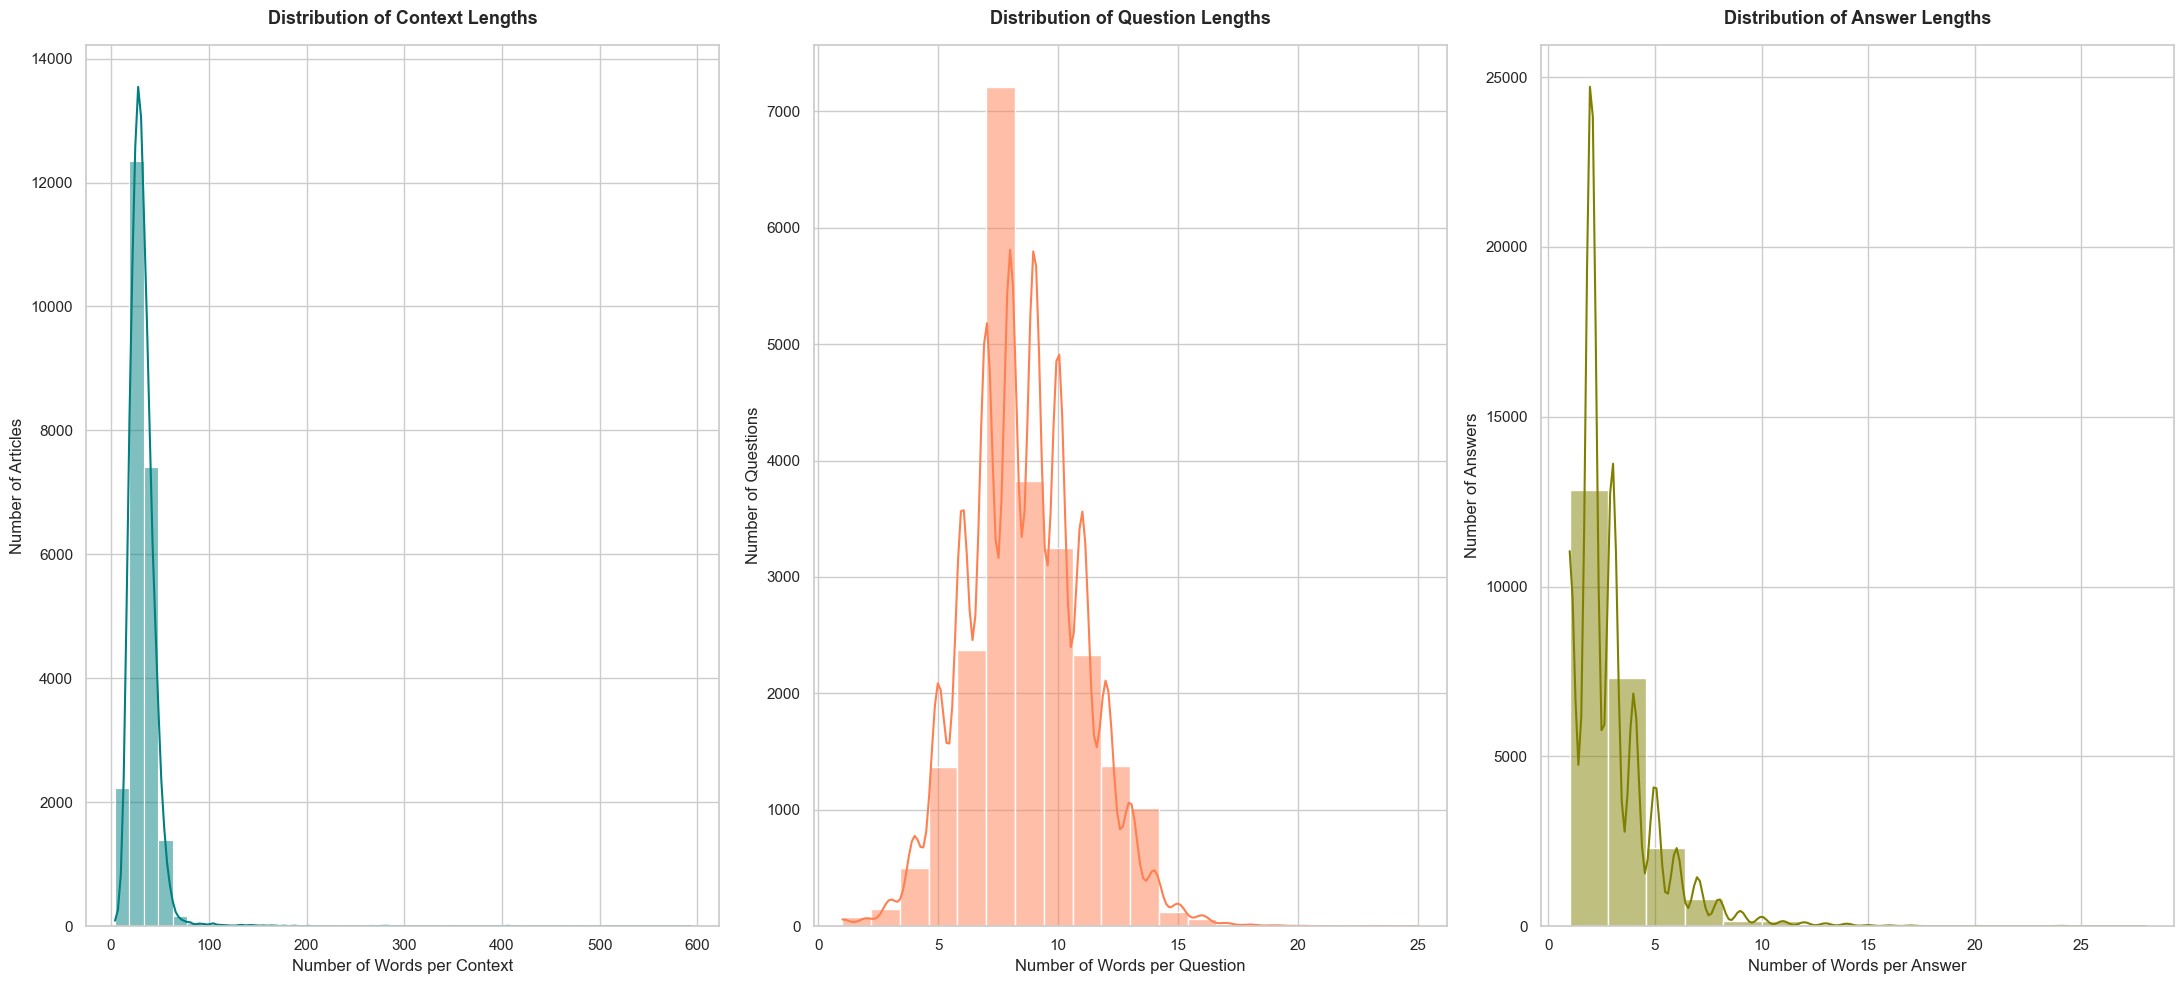

In [11]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(22, 10))

sns.histplot(data=df, x='context_len', bins=40, kde=True, color='teal', ax=axes[0])
axes[0].set_title('Distribution of Context Lengths', fontsize=13, pad=15, weight='bold')
axes[0].set_xlabel('Number of Words per Context')
axes[0].set_ylabel('Number of Articles')

sns.histplot(data=df, x='question_len', bins=20, kde=True, color='coral', ax=axes[1])
axes[1].set_title('Distribution of Question Lengths', fontsize=13, pad=15, weight='bold')
axes[1].set_xlabel('Number of Words per Question')
axes[1].set_ylabel('Number of Questions')

sns.histplot(data=df, x='answer_len', bins=15, kde=True, color='olive', ax=axes[2])
axes[2].set_title('Distribution of Answer Lengths', fontsize=13, pad=15, weight='bold')
axes[2].set_xlabel('Number of Words per Answer')
axes[2].set_ylabel('Number of Answers')

plt.tight_layout()

#### Type d'écriture

In [12]:
def categoriser_contexte(text):
    text = str(text)
    contient_arabe = bool(re.search(r'[\u0600-\u06FF]', text))
    contient_latin = bool(re.search(r'[a-zA-Z0-9\-\']', text))
    
    if contient_latin and contient_arabe:
        return "Code-Switching (Mixte)"
    elif contient_latin and not contient_arabe:
        return "100% Arabizi Pur"
    elif contient_arabe and not contient_latin:
        return "100% Alphabet Arabe"
    else:
        return "Autre / Bruit"

In [13]:
df['Linguistic_Type'] = df['context'].apply(categoriser_contexte)

In [14]:
df.groupby('Linguistic_Type').size()

Linguistic_Type
100% Alphabet Arabe       9367
100% Arabizi Pur          7126
Code-Switching (Mixte)    7209
dtype: int64

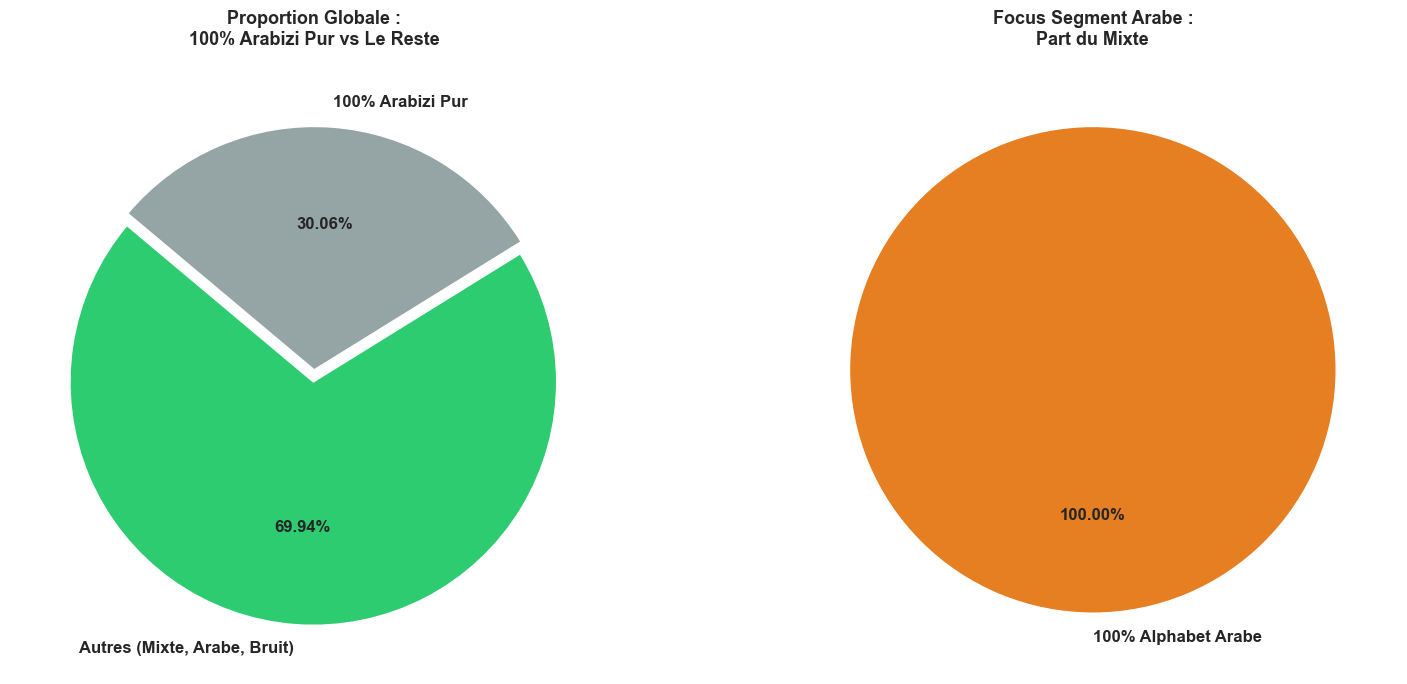

In [15]:
df['Linguistic_Type'] = df['context'].apply(categoriser_contexte)
df['Is_Pur_Arabizi'] = df['Linguistic_Type'].apply(lambda x: "100% Arabizi Pur" if x == "100% Arabizi Pur" else "Autres (Mixte, Arabe, Bruit)")
df_arabe = df[df['Linguistic_Type'].isin(["Mixte", "100% Alphabet Arabe"])]
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- Graphique 1 : Part du 100% Arabizi parmi TOUT le dataset ---
counts_pur = df['Is_Pur_Arabizi'].value_counts()
nb_categories_pur = len(counts_pur)
explode_pur = [0.05] + [0] * (nb_categories_pur - 1) if nb_categories_pur > 1 else [0]
colors_pie1 = ['#2ecc71', '#95a5a6'][:nb_categories_pur]

counts_pur.plot.pie(
    ax=axes[0], 
    autopct='%1.2f%%', 
    colors=colors_pie1, 
    startangle=140, 
    explode=explode_pur, 
    textprops={'fontsize': 12, 'weight': 'bold'}
)
axes[0].set_title("Proportion Globale :\n100% Arabizi Pur vs Le Reste", fontsize=13, weight='bold', pad=15)
axes[0].set_ylabel("")

# --- Graphique 2 : Part du Code-Switching parmi les textes contenant de l'Arabe ---
if not df_arabe.empty:
    counts_arabe = df_arabe['Linguistic_Type'].value_counts()
    nb_categories_arabe = len(counts_arabe)
    
    colors_pie2 = ['#e67e22', '#d35400'][:nb_categories_arabe]
    
    counts_arabe.plot.pie(
        ax=axes[1], 
        autopct='%1.2f%%', 
        colors=colors_pie2, 
        startangle=90, 
        textprops={'fontsize': 12, 'weight': 'bold'}
    )
    axes[1].set_title("Focus Segment Arabe :\nPart du Mixte", fontsize=13, weight='bold', pad=15)
    axes[1].set_ylabel("")
else:
    axes[1].text(0.5, 0.5, "Aucun caractère arabe trouvé\ndans tout le dataset !", ha='center', va='center', fontsize=12, color='green', weight='bold')
    axes[1].set_title("Focus Segment Arabe", fontsize=13, weight='bold', pad=15)

plt.tight_layout()
plt.show()

#### distribution des questions

C:\Users\exe\AppData\Local\Temp\ipykernel_31740\1929311928.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_debuts.values, y=fixed_labels, palette='viridis')


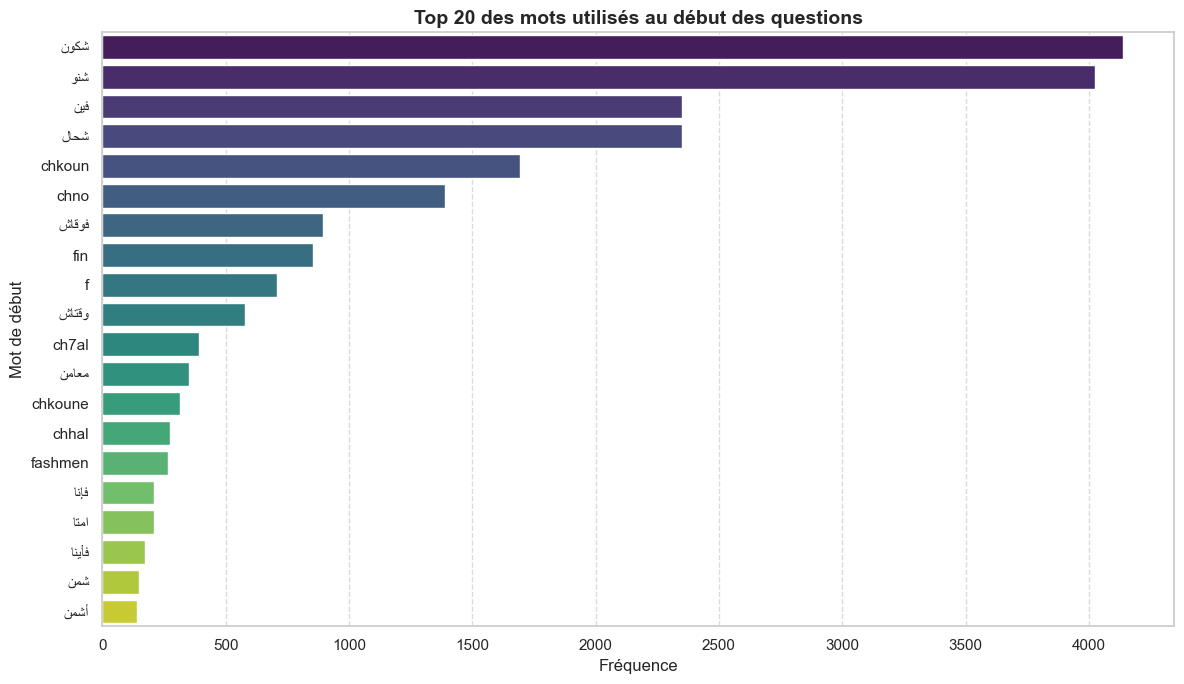

In [16]:
colonne_question = 'question'
def corriger_texte_arabe(texte):
    texte = str(texte)
    reshaped_text = arabic_reshaper.reshape(texte)
    bidi_text = get_display(reshaped_text)
    return bidi_text
df['debut_question'] = df[colonne_question].dropna().apply(
    lambda x: str(x).strip().split()[0].lower() if pd.notnull(x) and len(str(x).strip()) > 0 else None
)
df['debut_question'] = df['debut_question'].apply(corriger_texte_arabe)
# Compter les occurrences des premiers mots et garder le Top 20
top_debuts = df['debut_question'].value_counts().head(20)


fixed_labels = [label for label in top_debuts.index]

# Visualiser les résultats
plt.figure(figsize=(12, 7))
sns.barplot(x=top_debuts.values, y=fixed_labels, palette='viridis')

plt.title('Top 20 des mots utilisés au début des questions', fontsize=14, fontweight='bold')
plt.xlabel('Fréquence', fontsize=12)
plt.ylabel('Mot de début', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [17]:
df['debut_question'].apply(corriger_texte_arabe).unique()

array(['ﺷﻨﻮ', 'ﻓﺈﻧﺎ', 'ﺷﻜﻮﻥ', 'ﺃﺷﻤﻦ', 'ﻋﻠﻰ', 'ﺷﺤﺎﻝ', 'ﻓﻮﻗﺎﺵ', 'ﻓﻴﻦ', 'ﻣﻊ',
       'ﺇﻧﺎ', 'ﻓﺄﻳﻨﺎ', 'ﻓﺄﺷﻤﻦ', 'ﻣﻨﻴﻦ', 'ﺿﺪ', 'ﺑﺸﺤﺎﻝ', 'ﻓﺎﻳﻨﺎ', 'ﺑﺸﻨﻮ',
       'ﻟﺸﻜﻮﻥ', 'ﻓﺄﻱ', 'ﻣﻦ', 'ﻷﻳﻨﺎ', 'ﺃﻳﻨﺎ', 'ﻷﻱ', 'ﻓﺎﺷﻤﻦ', 'ﻓﺎﺵ', 'ﻟﻤﻦ',
       'ﻓﺄﻳﻦ', 'ﺍﻣﺘﺎ', 'ﻣﻌﺎﻣﻦ', 'ﻭﻗﺘﺎﺵ', 'ﻭ', 'ﺑﺎﺵ', 'ﻓﻴﺎ', 'f', 'chno',
       'chkoun', 'ch7al', 'fin', 'fashmen', 'fachman', 'fashman', 'mnin',
       'chkon', 'la', 'imta', 'chkun', '3lach', 'achmen', 'fay', 'chhal',
       'chkoune', 'fachmen', 'fiach', 'fina', 'fashmn', 'shkoun', 'lmen',
       "l'ay", 'fchno', 'chnou', 'chnu', 'qdam', 'bina2', 'fiachmen',
       'm3a', 'fachmn', '3la', 'fana', 'faya', 'fach', 'mn', 'lfine',
       'achno', 'chniya', 'kifach', 'l', 'ashmen', 'lfin', 'did', 'emta',
       'fayna', 'bchnou', 'la2ay', 'men', 'bsbab', 'menin', 'achnou',
       'liman', 'hata', 'fayen', 'bchmen', "f'achmn", 'b', 'hatta',
       'bayn', 'taht', 'fiyachmn', 'f7okomat', 'rraqm', 'ach', "f'achmen",
       'fiyach', 'l2ay', 'bach', 'achmn', 'lman', 'had', 

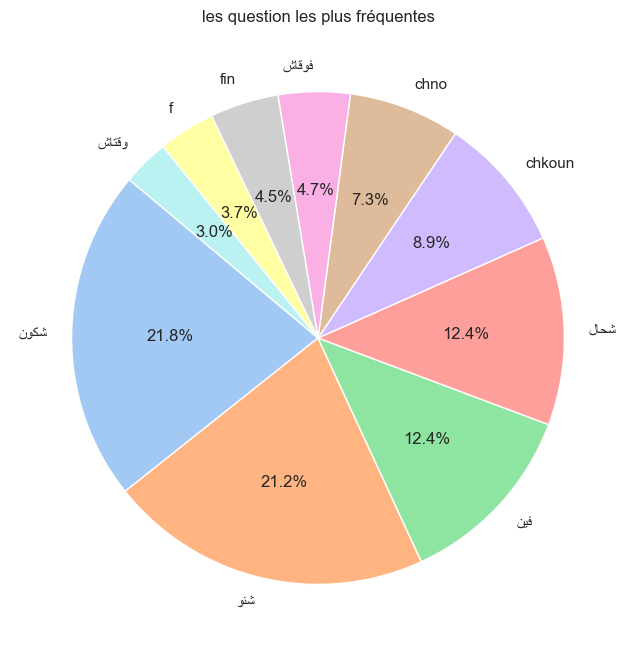

In [18]:
# Prendre les 10 premiers mots pour que le diagramme reste lisible
top_debuts_pie = df['debut_question'].value_counts().head(10)

# 1. Appliquer fix_arabic à chaque label en utilisant une compréhension de liste
fixed_labels = [label for label in top_debuts_pie.index]

# Créer le diagramme circulaire
plt.figure(figsize=(10, 8))
plt.pie( 
    top_debuts_pie.values, 
    labels=fixed_labels,  # 2. Utiliser la nouvelle liste corrigée ici
    autopct='%1.1f%%',        
    startangle=140,           
    colors=sns.color_palette('pastel', len(top_debuts_pie)), 
    wedgeprops={'edgecolor': 'white', 'linewidth': 1} 
)

plt.title("les question les plus fréquentes")

plt.show()